In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
from pathlib import Path

DATA_PATH = Path.cwd().parent / "data" / "code_classification_dataset"
files = os.listdir(DATA_PATH)

print(len(files))

4982


In [12]:
import json

idx = 0

with open(DATA_PATH / files[2]) as f:
    d = json.load(f)

print(d.keys())

dict_keys(['prob_desc_time_limit', 'prob_desc_sample_outputs', 'src_uid', 'prob_desc_notes', 'prob_desc_description', 'prob_desc_output_spec', 'prob_desc_input_spec', 'prob_desc_output_to', 'prob_desc_input_from', 'lang', 'lang_cluster', 'difficulty', 'file_name', 'code_uid', 'prob_desc_memory_limit', 'prob_desc_sample_inputs', 'exec_outcome', 'source_code', 'prob_desc_created_at', 'tags', 'hidden_unit_tests'])


In [15]:
d["src_uid"]

'7b12845f668e28b7f18019d5ab5eaec7'

In [14]:
d["tags"]

['sortings', 'greedy']

In [8]:
d["prob_desc_notes"]

'NoteIn the example, one of the possible Hamiltonian cycles with length 6 is (1, 1) (1, 2) (2, 1) (2, 2). There does not exist any other Hamiltonian cycle with a length greater than 6.The Manhattan distance between two cities (xi,\u2009yi) and (xj,\u2009yj) is |xi\u2009-\u2009xj|\u2009+\u2009|yi\u2009-\u2009yj|.'

In [16]:
from collections import Counter

classes = Counter()

desc = []
tags = []
uids = []


for file in files:
    with open(DATA_PATH / file) as f:
        d = json.load(f)

    text = d["source_code"]
    labels = set(d["tags"])
    uids.append(d["src_uid"])

    classes.update(labels)

    desc.append(text)
    tags.append(labels)
    

In [54]:
target_tags = {
    "math", "graphs", "strings", "number theory", "trees", "geometry", "games", "probabilities"
}

for t in target_tags:
    print(f"Number of elements of tag {t}: {classes.get(t)}")

Number of elements of tag math: 1408
Number of elements of tag number theory: 350
Number of elements of tag graphs: 542
Number of elements of tag games: 105
Number of elements of tag trees: 324
Number of elements of tag geometry: 166
Number of elements of tag probabilities: 92
Number of elements of tag strings: 422


In [58]:
Counter([tuple(t & target_tags) for t in tags])

Counter({(): 2304,
         ('math',): 929,
         ('strings',): 353,
         ('graphs',): 332,
         ('math', 'number theory'): 222,
         ('trees',): 147,
         ('trees', 'graphs'): 107,
         ('geometry',): 95,
         ('number theory',): 69,
         ('games',): 60,
         ('math', 'geometry'): 53,
         ('math', 'graphs'): 46,
         ('math', 'probabilities'): 36,
         ('probabilities',): 34,
         ('math', 'strings'): 32,
         ('math', 'games'): 17,
         ('math', 'trees'): 15,
         ('trees', 'strings'): 11,
         ('math', 'number theory', 'graphs'): 11,
         ('strings', 'graphs'): 9,
         ('math', 'trees', 'graphs'): 7,
         ('number theory', 'graphs'): 7,
         ('math', 'number theory', 'games'): 6,
         ('trees', 'games'): 5,
         ('math', 'probabilities', 'number theory'): 5,
         ('math', 'trees', 'number theory'): 5,
         ('trees', 'number theory'): 4,
         ('geometry', 'graphs'): 4,
         ('m

In [14]:
from sentence_transformers import SentenceTransformer

# Load the model
model = SentenceTransformer("Qwen/Qwen3-Embedding-8B")

W1117 10:59:34.462000 49848 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [19]:
tokenizer = model.tokenizer
tokens = [model.tokenizer(i)["input_ids"] for i in desc]

In [22]:
sum([len(i) for i in tokens]) / len(tokens) * 64

25365.106382978724

In [18]:
tokens[0].keys()

KeysView({'input_ids': [2, 11047, 65930, 315, 29372, 348, 624, 2, 348, 374, 1140, 315, 68025, 2498, 369, 3501, 624, 750, 65930, 3747, 11, 17986, 28, 16, 68, 12, 23, 7731, 262, 671, 7807, 279, 10320, 1459, 198, 262, 348, 10614, 4857, 27504, 856, 3269, 87, 29791, 12803, 70977, 1171, 262, 348, 284, 348, 58, 15, 25, 16, 60, 488, 10615, 3747, 58, 16, 45499, 1376, 27504, 856, 3269, 87, 8273, 58, 15, 10697, 28016, 14, 3435, 2075, 8273, 58, 15, 36928, 262, 308, 284, 220, 16, 198, 262, 369, 600, 304, 2088, 7, 17, 11, 2422, 3747, 9957, 286, 1393, 308, 861, 220, 16, 323, 1781, 85, 7669, 11696, 85, 7669, 12, 16, 2467, 6599, 85, 989, 11696, 85, 7669, 10697, 443, 47702, 349, 6011, 28016, 38643, 7124, 510, 310, 308, 5982, 220, 16, 198, 286, 770, 510, 310, 308, 1421, 220, 16, 198, 310, 348, 7669, 60, 284, 348, 989, 2533, 262, 348, 7669, 10, 16, 28283, 284, 14599, 262, 470, 348, 271, 2, 11047, 279, 3082, 315, 264, 29372, 348, 11, 7147, 54288, 4482, 624, 2, 348, 374, 1140, 315, 68025, 2498, 369, 3501, 6

In [23]:
emb = model.encode(desc[:10])

In [31]:
embs = []
bs = 64
n = len(desc) // bs

for i in range(n):
    texts = desc[i*bs:(i+1)*bs]
    emb = model.encode(texts)
    embs.append(emb)

In [38]:
import numpy as np
import umap

embs = np.concatenate(embs)
uembs = umap.UMAP().fit_transform(embs)

/Users/etienneguevel/Documents/projects/illuin_tt/.venv/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)


In [40]:
c = Counter([len(i) for i in tags])
c

Counter({2: 1456,
         3: 1271,
         1: 858,
         4: 774,
         5: 338,
         6: 165,
         7: 57,
         0: 41,
         8: 15,
         9: 6,
         11: 1})

In [49]:
import pandas as pd

df_plot = pd.DataFrame(
    [(e[0], e[1], [i for i in t if i in target_tags]) for e, t in zip(uembs, tags[:len(uembs)])],
    columns=["x", "y", "tags"]
)

df_plot["first_tag"] = df_plot.tags.apply(lambda y: y[0] if len(y) > 0 else "other")

df_plot.head(10)

,x,y,tags,first_tag
0,8.763162,9.800199,[geometry],geometry
1,8.587295,7.673642,[],other
2,3.794294,8.709844,[],other
3,2.589349,11.533340,[],other
4,-0.650404,7.762500,[strings],strings
5,7.933333,8.051061,[],other
6,5.796320,8.826795,"[math, number theory]",math
7,5.531728,10.177349,[],other
8,3.643886,7.356228,[],other
9,0.075233,7.153207,"[strings, math]",strings


In [51]:
df_plot.first_tag.value_counts()

first_tag
other            2277
math             1297
graphs            400
strings           368
trees             222
number theory     143
geometry          114
games              64
probabilities      43
Name: count, dtype: int64

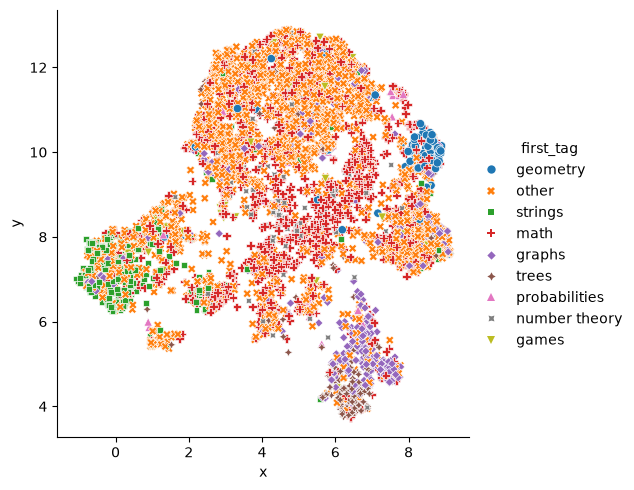

In [52]:
import seaborn as sns

sns.relplot(df_plot, x="x", y="y", style="first_tag", hue="first_tag")

In [ ]:
def one_hot_encode(tags: list[set[str]], categories: set[str]):
    output = [[1 if c in t else 0 for c in categories] for t in tags]

    return np.array(output)

In [91]:
from skmultilearn.model_selection import iterative_train_test_split

# X: 2D array/sparse matrix of features, y: 2D binary indicator matrix of labels
X_train, y_train, X_test, y_test = iterative_train_test_split(
    np.array(desc).reshape(-1, 1), test, test_size=0.2
)


In [77]:
y_train[:, 0]

array([0, 0, 0, ..., 1, 0, 1], shape=(3942,))

In [82]:
from tqdm import tqdm

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

models = {}
eval_metrics = {}

for k, i in tqdm(enumerate(target_tags)):
    estimator = LogisticRegression()
    y = y_train[:, k]

    # Train the model
    estimator.fit(X_train, y)
    models[i] = estimator

    # Evaluate the model
    preds = estimator.predict(X_test)
    metrics = classification_report(y_test[:, k], preds)
    print(i.upper(), metrics)

    eval_metrics[i] = metrics


8it [00:00, 37.82it/s]

MATH               precision    recall  f1-score   support

           0       0.82      0.93      0.87       707
           1       0.73      0.49      0.59       279

    accuracy                           0.81       986
   macro avg       0.78      0.71      0.73       986
weighted avg       0.80      0.81      0.79       986

NUMBER THEORY               precision    recall  f1-score   support

           0       0.96      0.99      0.97       916
           1       0.79      0.44      0.57        70

    accuracy                           0.95       986
   macro avg       0.88      0.72      0.77       986
weighted avg       0.95      0.95      0.95       986

GRAPHS               precision    recall  f1-score   support

           0       0.94      0.99      0.96       879
           1       0.80      0.50      0.61       107

    accuracy                           0.93       986
   macro avg       0.87      0.74      0.79       986
weighted avg       0.93      0.93      0.92     

In [79]:
eval_metrics

{}